# BaTiO$_3$ paper figures

Run all cells with **Python (of_dev)**. The four individual convergence PNGs and the
four-panel 3D PNG are saved at 300 dpi in `figures/` and copied into the sibling `openferro_overleaf`
checkout when present.

The FES estimate is the negative sum of deposited Gaussian hills. Convergence
cuts use the five common time checkpoints, each curve's minimum is zero, and
each panel has its own polarization window with a 0–200 meV energy range.
The 3D panels show $\Delta F\leq200\,\mathrm{meV}$, recovered by cubic signed permutations.
These finite-run estimates remain subject to sampling and wall effects;
the displayed symmetry variants are not independently sampled basins.

In [ ]:
from pathlib import Path
import json
import shutil

import numpy as np
import matplotlib.pyplot as plt

# Temperature (K), phase, cut direction, x limits (microC/cm^2).
PANELS = [
    (180, 'Rhombohedral', (1, 1, 1), (32, 44)),
    (220, 'Orthorhombic', (1, 1, 0), (26, 40)),
    (250, 'Tetragonal', (1, 0, 0), (20, 34)),
    (310, 'Cubic', (1, 0, 0), (0, 20)),
]
TIMES_NS = np.array([0.5, 1.5, 2.5, 3.5, 4.5])
GRID_POINTS = 129
DISPLAY_STRIDE = 4
LOW_ENERGY_MEV = 200.0
P_SCALE = 100.0  # 1 C/m^2 = 100 microC/cm^2.

candidates = [Path.cwd(), Path.cwd() / '08.BTO_MetaD', Path.cwd() / 'examples/08.BTO_MetaD']
EXAMPLE_DIR = next(p.resolve() for p in candidates if (p / 'T180/HILLS').is_file())
OUTPUT_DIR = EXAMPLE_DIR / 'figures'
OVERLEAF_DIR = EXAMPLE_DIR.parents[2] / 'openferro_overleaf'
OUTPUT_DIR.mkdir(exist_ok=True)
runs = {}
for temperature, *_ in PANELS:
    directory = EXAMPLE_DIR / f'T{temperature}'
    settings = json.loads((directory / 'settings.json').read_text())
    hills = np.loadtxt(directory / 'HILLS', comments='#', ndmin=2)
    times_ns = hills[:, 0] * settings['metadynamics']['dt_ps'] / 1000
    if times_ns[-1] + 1e-12 < TIMES_NS[-1]:
        raise ValueError(f'{temperature} K: HILLS ends before the last requested checkpoint.')
    runs[temperature] = (hills, times_ns)

plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 10, 'axes.titlesize': 10,
    'legend.fontsize': 8, 'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
})
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

In [20]:
def bias_at_points(points, hills):
    """Sum the logged Gaussians at q points; energies are total supercell eV."""
    bias = np.zeros(len(points))
    for start in range(0, len(hills), 256):
        block = hills[start:start + 256]
        delta = (points[:, None, :] - block[None, :, 1:4]) / block[None, :, 4:7]
        bias += np.exp(-0.5 * np.sum(delta**2, axis=2)) @ block[:, 7]
    return bias


def bias_on_grid(axis, hills):
    """Evaluate the exact Gaussian sum on a regular q grid using separability."""
    n = len(axis)
    bias = np.zeros((n, n, n))
    for start in range(0, len(hills), 256):
        block = hills[start:start + 256]
        factors = [np.exp(-0.5 * ((axis[:, None] - block[None, :, i + 1])
                                  / block[None, :, i + 4])**2) for i in range(3)]
        xy = (factors[0][:, None, :] * factors[1][None, :, :]
              * block[None, None, :, 7]).reshape(n * n, -1)
        bias += (xy @ factors[2].T).reshape(bias.shape)
    return bias


def save_png(figure, name):
    path = OUTPUT_DIR / f'{name}.png'
    figure.savefig(path, dpi=300, bbox_inches='tight', facecolor='white')
    if OVERLEAF_DIR.is_dir():
        shutil.copy2(path, OVERLEAF_DIR / path.name)

## Convergence

For a unit direction $\widehat{\mathbf n}$, the horizontal coordinate is
$p=|\mathbf P|$, with $\mathbf P=p\widehat{\mathbf n}$ and
$\mathbf q=(P_x-P_y,P_y-P_z,P_z)$. Each curve uses all hills deposited at or
before its labeled time and is shifted by its own minimum along the cut.

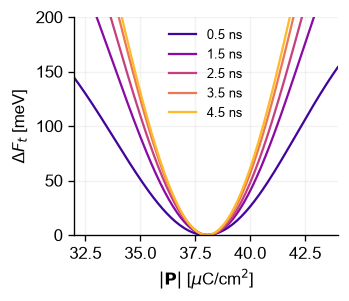

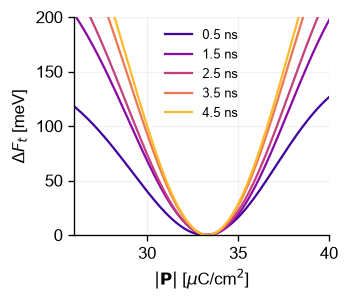

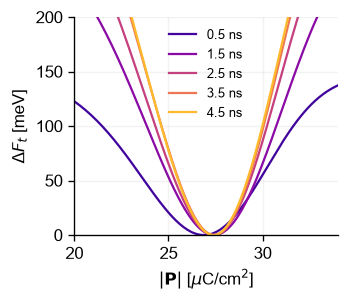

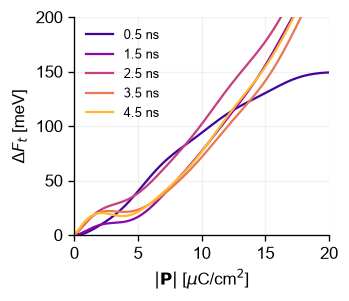

In [27]:
profile_p = np.linspace(0, 0.44, 441)  # C/m^2; includes both sides of the [111] well.
colors = plt.cm.plasma(np.linspace(0.1, 0.85, len(TIMES_NS)))
for panel, (temperature, phase, direction, xlim) in enumerate(PANELS):
    figure_convergence, axis = plt.subplots(figsize=(2.8, 2.4), layout='constrained')
    hills, times_ns = runs[temperature]
    direction = np.asarray(direction, dtype=float)
    polarization = profile_p[:, None] * direction / np.linalg.norm(direction)
    q = np.column_stack((polarization[:, 0] - polarization[:, 1],
                         polarization[:, 1] - polarization[:, 2], polarization[:, 2]))
    for time_ns, color in zip(TIMES_NS, colors):
        count = np.searchsorted(times_ns, time_ns + 1e-12, side='right')
        energy = -bias_at_points(q, hills[:count])
        energy -= energy.min()
        axis.plot(profile_p * P_SCALE, energy * 1000, color=color, lw=1.35, label=f'{time_ns:.1f} ns')
    axis.set(xlim=xlim, ylim=(0, 200), yticks=[0, 50, 100, 150, 200])
    axis.set_xlabel(r'$|\mathbf{P}|$ [$\mu$C/cm$^2$]', fontsize=10)
    axis.set_ylabel(r'$\Delta F_t$ [meV]', fontsize=10)
    axis.grid(alpha=0.16)
    axis.legend(fontsize=8, frameon=False)
    save_png(figure_convergence, f'bto_metadynamics_convergence_{temperature}K')
    plt.show()

## Three-dimensional symmetry

For any $\mathbf P$, sort its absolute components to obtain $a\geq b\geq c$,
then evaluate the chamber FES at $(q_1,q_2,q_3)=(a-b,b-c,c)$. The chamber
transformation has unit Jacobian. This symmetry extension assumes the cubic
Hamiltonian under hydrostatic pressure.

Following `analyze.ipynb`, plot the low-energy grid points as a 3D scatter
cloud, colored by free energy with `viridis`. All panels share one energy
color scale, the same viewing angle, and equal axis limits. The selection
remains $\Delta F\leq200\,\mathrm{meV}$ at each temperature; `DISPLAY_STRIDE` controls
point density without changing the reconstructed FES.


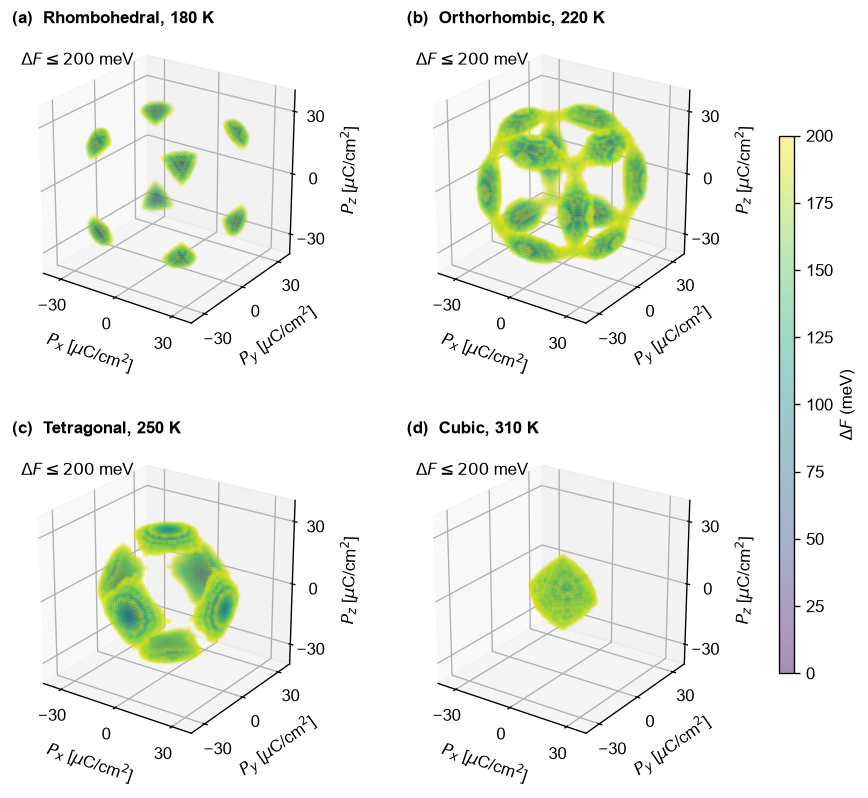

In [23]:
q_axis = np.linspace(0, 0.4, GRID_POINTS)  # C/m^2.
i, j, k = np.ogrid[:GRID_POINTS, :GRID_POINTS, :GRID_POINTS]
nominal = i + j + k < GRID_POINTS  # Px = q1 + q2 + q3 <= 0.4 C/m^2.
absolute_indices = np.abs(np.indices((2 * GRID_POINTS - 1,) * 3, dtype=np.int16) - (GRID_POINTS - 1))
a, b, c = np.sort(absolute_indices, axis=0)[::-1]
display_axis = np.linspace(-0.4, 0.4, 2 * GRID_POINTS - 1)[::DISPLAY_STRIDE] * P_SCALE
color_max_meV = LOW_ENERGY_MEV
figure_symmetry = plt.figure(figsize=(7.0, 7.0))
layout = figure_symmetry.add_gridspec(2, 2, left=0.015, right=0.87, bottom=0.09, top=0.94,
                                     wspace=0.22, hspace=0.35)
for panel, (temperature, phase, _, _) in enumerate(PANELS):
    bias = bias_on_grid(q_axis, runs[temperature][0])
    chamber_energy = bias[nominal].max() - bias
    energy = chamber_energy[a - b, b - c, c]
    display_energy = energy[::DISPLAY_STRIDE, ::DISPLAY_STRIDE, ::DISPLAY_STRIDE]
    cutoff = LOW_ENERGY_MEV / 1000
    low_energy = display_energy <= cutoff
    points = display_axis[np.argwhere(low_energy)]
    axis = figure_symmetry.add_subplot(layout[panel // 2, panel % 2], projection='3d')
    image = axis.scatter(*points.T, c=display_energy[low_energy] * 1000,
                         cmap='viridis', vmin=0, vmax=color_max_meV, s=4, alpha=0.45)
    axis.set(xlim=(-40, 40), ylim=(-40, 40), zlim=(-40, 40),
             xlabel=r'$P_x$ [$\mu$C/cm$^2$]', ylabel=r'$P_y$ [$\mu$C/cm$^2$]',
             zlabel=r'$P_z$ [$\mu$C/cm$^2$]')
    for coordinate_axis in (axis.xaxis, axis.yaxis, axis.zaxis):
        coordinate_axis.set_ticks([-30, 0, 30])
        coordinate_axis.label.set_size(10)
        coordinate_axis.labelpad = 1
    axis.set_box_aspect((1, 1, 1))
    axis.view_init(elev=24, azim=-55)
    axis.tick_params(pad=0)
    axis.set_title(f'({chr(97 + panel)})  {phase}, {temperature} K', loc='left', weight='bold', pad=7)
    axis.text2D(0.03, 0.90, rf'$\Delta F\leq {LOW_ENERGY_MEV:g}$ meV',
                transform=axis.transAxes, fontsize=10)
figure_symmetry.colorbar(image, cax=figure_symmetry.add_axes([0.94, 0.18, 0.018, 0.64]),
                         label=r'$\Delta F$ (meV)')
save_png(figure_symmetry, 'bto_metadynamics_symmetry')
plt.show()
